1. **Churn Classification (Supervised - Binary Classification):** Predict whether a customer will churn (`1`) or stay (`0`). To make the model realistic and avoid synthetic 100% accuracy, we exclude deterministic columns (`Support Calls`, `Payment Delay`) and data leakage (`Last Interaction`).
2. **Total Spend Regression (Supervised - Continuous Regression):** Predict a customer's lifetime value/expenditure (`Total Spend`) based on their behavior. 

- **For Classification:**
  - Logistic Regression (Baseline)
  - Decision Tree Classifier
  - Random Forest Classifier
- **For Regression:**
  - Linear Regression (Baseline)
  - Decision Tree Regressor
  - Random Forest Regressor


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, precision_recall_curve, auc,
    mean_absolute_error, mean_squared_error
)

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Create plots folder if it doesn't exist
os.makedirs('plots', exist_ok=True)
print("Environment set up successfully. Plots folder verified/created.")


Environment set up successfully. Plots folder verified/created.


## 1. Preprocessing & Data Cleaning

### 1.1 Data Load and Initial Exploration
We load the training dataset, drop the single corrupted empty row, and correct the data types.


In [2]:
# Load training data
df_train = pd.read_csv('customer_churn_dataset-training-master.csv')
print(f"Raw training dataset shape: {df_train.shape}")

# Drop the completely empty row (where all values are null)
empty_row_idx = df_train[df_train.isnull().all(axis=1)].index.tolist()
print(f"Empty row index found: {empty_row_idx}")
df_clean = df_train.dropna(how='all').copy()
print(f"Shape after dropping empty row: {df_clean.shape}")

# Data Type Corrections
int_cols = ['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Last Interaction', 'Churn']
for col in int_cols:
    df_clean[col] = df_clean[col].astype('int64')

str_cols = ['Gender', 'Subscription Type', 'Contract Length']
for col in str_cols:
    df_clean[col] = df_clean[col].astype(str)

print("\nData types corrected. Categoricals converted to string. Target variable is now int64.")


Raw training dataset shape: (440833, 12)
Empty row index found: [199295]
Shape after dropping empty row: (440832, 12)

Data types corrected. Categoricals converted to string. Target variable is now int64.


### 1.2 Feature Engineering
We construct the engineered features:
1. `spend_per_month` = `Total Spend` / `Tenure` (expenditure rate)
2. `support_rate` = `Support Calls` / `Tenure` (frequency of support relative to lifespan)
3. `is_high_risk` = `1` if `Payment Delay` > 20 AND `Support Calls` > 7, else `0` (compound risk flag)


In [3]:
# Apply feature engineering (consistent with EDA)
df_clean['spend_per_month'] = df_clean['Total Spend'] / df_clean['Tenure']
df_clean['support_rate'] = df_clean['Support Calls'] / df_clean['Tenure']
df_clean['is_high_risk'] = ((df_clean['Payment Delay'] > 20) & (df_clean['Support Calls'] > 7)).astype(int)

print("Engineered features created.")
display(df_clean[['Total Spend', 'Tenure', 'spend_per_month', 'Support Calls', 'support_rate', 'Payment Delay', 'is_high_risk']].head(3))


Engineered features created.


,Total Spend,Tenure,spend_per_month,Support Calls,support_rate,Payment Delay,is_high_risk
0,932.0,39,23.897436,5,0.128205,18,0
1,557.0,49,11.367347,10,0.204082,8,0
2,185.0,14,13.214286,6,0.428571,18,0


### 1.3 Categorical Encoding
We convert categorical features to numerical scales:
- `Contract Length` mapping: `{'Monthly': 0, 'Quarterly': 1, 'Annual': 2}` (preserving contract length ordering)
- `Subscription Type` mapping: `{'Basic': 0, 'Standard': 1, 'Premium': 2}`
- `Gender` mapping: `{'Female': 0, 'Male': 1}`


In [4]:
# Categorical Mapping
contract_mapping = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
sub_mapping = {'Basic': 0, 'Standard': 1, 'Premium': 2}
gender_mapping = {'Female': 0, 'Male': 1}

df_clean['Contract Length'] = df_clean['Contract Length'].map(contract_mapping)
df_clean['Subscription Type'] = df_clean['Subscription Type'].map(sub_mapping)
df_clean['Gender'] = df_clean['Gender'].map(gender_mapping)

print("Categorical encoding complete.")


Categorical encoding complete.


## 2. Part 1: Churn Classification

### 2.1 Split and Scale (Classification)
We define `Churn` as our target, and split the data into an **80/20 train/test split** (stratified, `random_state=42`). 
We drop `CustomerID`, `Last Interaction`, `Support Calls`, and `Payment Delay` to remove leakage and synthetic rules.


In [5]:
# Define features and target for classification
X_clf = df_clean.drop(columns=['CustomerID', 'Churn', 'Last Interaction', 'Support Calls', 'Payment Delay', 'is_high_risk', 'support_rate'])
y_clf = df_clean['Churn']

# Split data: 80% train, 20% validation
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, stratify=y_clf, random_state=42
)

# Normalize continuous features
clf_features_to_scale = ['Age', 'Tenure', 'Usage Frequency', 'Total Spend', 'spend_per_month']
scaler_clf = MinMaxScaler()

X_train_clf_scaled = X_train_clf.copy()
X_test_clf_scaled = X_test_clf.copy()

X_train_clf_scaled[clf_features_to_scale] = scaler_clf.fit_transform(X_train_clf[clf_features_to_scale])
X_test_clf_scaled[clf_features_to_scale] = scaler_clf.transform(X_test_clf[clf_features_to_scale])

print("Classification features selected:")
print(X_clf.columns.tolist())


Classification features selected:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Subscription Type', 'Contract Length', 'Total Spend', 'spend_per_month']


### 2.2 Model Training (Classification)
We train Logistic Regression, a Decision Tree, and a Random Forest.


In [6]:
# 1. Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_clf_scaled, y_train_clf)

# 2. Decision Tree Classifier (max_depth=5)
dt_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_clf.fit(X_train_clf_scaled, y_train_clf)

# 3. Random Forest Classifier (max_depth=15, n_estimators=100)
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_clf.fit(X_train_clf_scaled, y_train_clf)

print("Classification models successfully trained.")


Classification models successfully trained.


### 2.3 Evaluation (Classification)
We predict on the test split and evaluate using classification metrics.


In [7]:
# Gather predictions and probabilities
clf_models = {
    'Logistic Regression': log_reg,
    'Decision Tree': dt_clf,
    'Random Forest': rf_clf
}

clf_metrics_list = []
clf_results = {}

for name, model in clf_models.items():
    preds = model.predict(X_test_clf_scaled)
    probs = model.predict_proba(X_test_clf_scaled)[:, 1]
    
    acc = accuracy_score(y_test_clf, preds)
    prec = precision_score(y_test_clf, preds)
    rec = recall_score(y_test_clf, preds)
    f1 = f1_score(y_test_clf, preds)
    roc_auc = roc_auc_score(y_test_clf, probs)
    
    clf_metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })
    
    clf_results[name] = {
        'preds': preds,
        'probs': probs
    }

# Create classification metrics table
df_clf_metrics = pd.DataFrame(clf_metrics_list)
print("Classification Evaluation Metrics:")
display(df_clf_metrics.style.background_gradient(cmap='Blues'))


Classification Evaluation Metrics:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.753649,0.781898,0.784400,0.783147,0.836738
1,Decision Tree,0.873524,0.999923,0.777040,0.874503,0.919051
2,Random Forest,0.887464,0.999302,0.802120,0.889919,0.930579


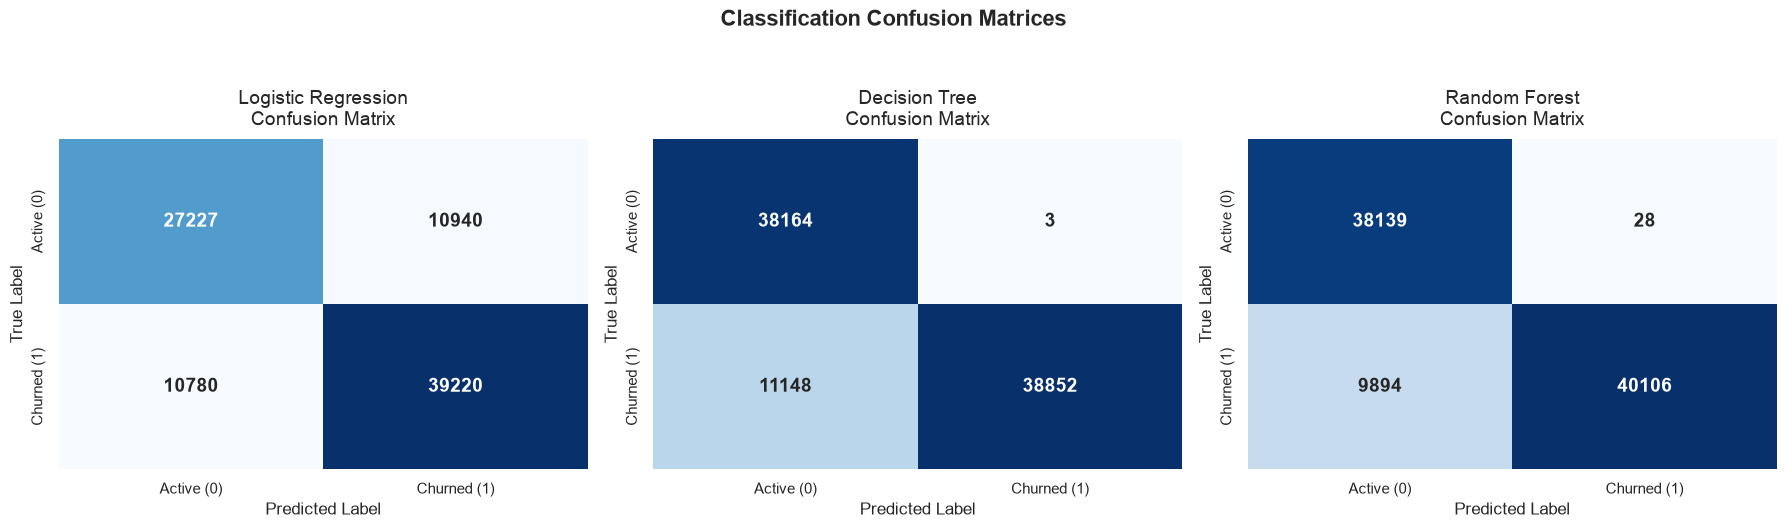

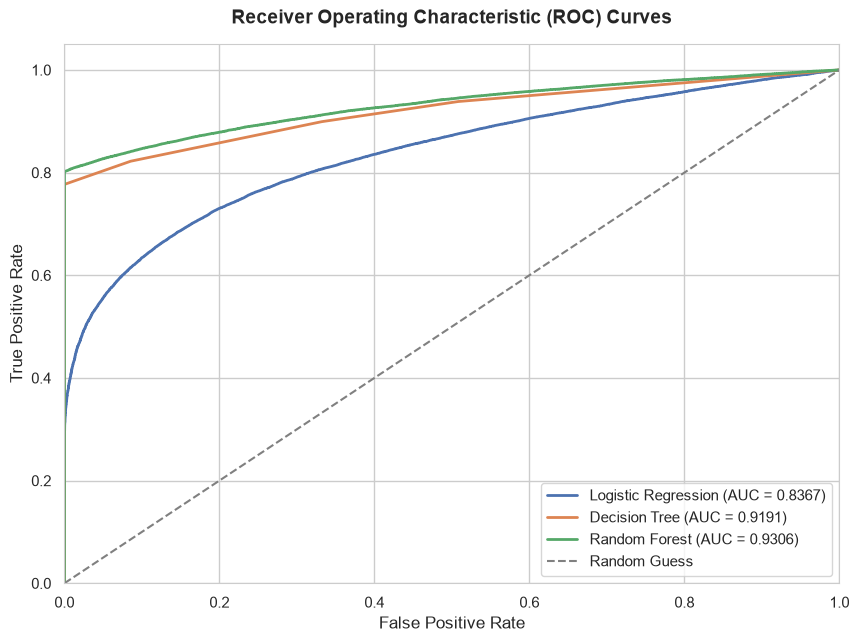

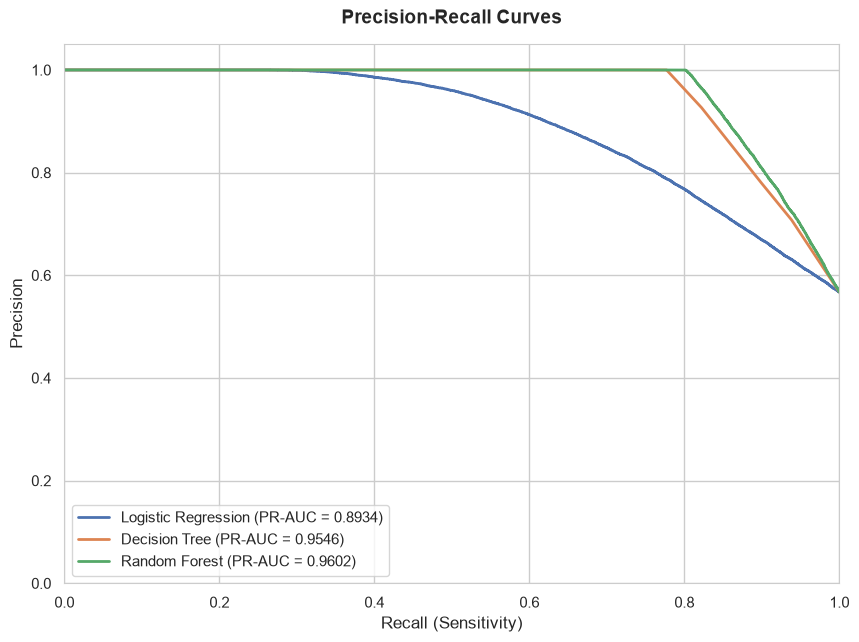

In [8]:
# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, res) in enumerate(clf_results.items()):
    cm = confusion_matrix(y_test_clf, res['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    axes[idx].set_title(f'{name}\nConfusion Matrix', fontsize=14, pad=10)
    axes[idx].set_xlabel('Predicted Label', fontsize=12)
    axes[idx].set_ylabel('True Label', fontsize=12)
    axes[idx].set_xticklabels(['Active (0)', 'Churned (1)'])
    axes[idx].set_yticklabels(['Active (0)', 'Churned (1)'])

plt.suptitle('Classification Confusion Matrices', fontsize=16, y=1.05, weight='bold')
plt.tight_layout()
plt.savefig('plots/confusion_matrices.png', bbox_inches='tight')
plt.show()

# 2. ROC Curves Comparison
plt.figure(figsize=(10, 7))
for name, res in clf_results.items():
    fpr, tpr, _ = roc_curve(y_test_clf, res['probs'])
    auc_val = roc_auc_score(y_test_clf, res['probs'])
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, weight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.savefig('plots/roc_curves.png', bbox_inches='tight')
plt.show()

# 3. Precision-Recall Curves
plt.figure(figsize=(10, 7))
for name, res in clf_results.items():
    precision, recall, _ = precision_recall_curve(y_test_clf, res['probs'])
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, lw=2, label=f'{name} (PR-AUC = {pr_auc:.4f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curves', fontsize=14, weight='bold', pad=15)
plt.legend(loc="lower left", fontsize=11)
plt.savefig('plots/precision_recall_curves.png', bbox_inches='tight')
plt.show()


## 3. Part 2: Spend Regression

### 3.1 Split and Scale (Regression)
We define the continuous feature `Total Spend` as our regression target. We predict customer lifetime spend based on behavioral attributes (`Age`, `Gender`, `Tenure`, `Usage Frequency`, `Subscription Type`, `Contract Length`). We split 80/20.


In [9]:
# Define features and target for regression
X_reg = df_clean.drop(columns=['CustomerID', 'Total Spend', 'Last Interaction', 'Churn', 'spend_per_month', 'support_rate', 'is_high_risk'], errors='ignore')
y_reg = df_clean['Total Spend']

# Split data: 80% train, 20% validation
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Normalize continuous features
reg_features_to_scale = ['Age', 'Tenure', 'Usage Frequency']
scaler_reg = MinMaxScaler()

X_train_reg_scaled = X_train_reg.copy()
X_test_reg_scaled = X_test_reg.copy()

X_train_reg_scaled[reg_features_to_scale] = scaler_reg.fit_transform(X_train_reg[reg_features_to_scale])
X_test_reg_scaled[reg_features_to_scale] = scaler_reg.transform(X_test_reg[reg_features_to_scale])

print("Regression features selected:")
print(X_reg.columns.tolist())


Regression features selected:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length']


### 3.2 Model Training (Regression)
We train Linear Regression, a Decision Tree Regressor, and a Random Forest Regressor.


In [10]:
# 1. Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg_scaled, y_train_reg)

# 2. Decision Tree Regressor (max_depth=5)
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_reg.fit(X_train_reg_scaled, y_train_reg)

# 3. Random Forest Regressor (max_depth=10, n_estimators=50)
rf_reg = RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
rf_reg.fit(X_train_reg_scaled, y_train_reg)

print("Regression models successfully trained.")


Regression models successfully trained.


### 3.3 Evaluation (Regression)
We evaluate the regressor models on the test split using the regression metrics:
- **Mean Absolute Error (MAE)**
- **Mean Absolute Percentage Error (MAPE)**
- **Mean Squared Error (MSE)**
- **Root Mean Squared Error (RMSE)**
- **Weighted Absolute Percentage Error (WAPE)**


In [11]:
reg_models = {
    'Linear Regression': lin_reg,
    'Decision Tree Regressor': dt_reg,
    'Random Forest Regressor': rf_reg
}

reg_metrics_list = []
reg_results = {}

for name, model in reg_models.items():
    preds = model.predict(X_test_reg_scaled)
    
    mae = mean_absolute_error(y_test_reg, preds)
    mse = mean_squared_error(y_test_reg, preds)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_test_reg - preds) / y_test_reg)) * 100
    wape = np.sum(np.abs(y_test_reg - preds)) / np.sum(y_test_reg) * 100
    
    reg_metrics_list.append({
        'Model': name,
        'MAE': mae,
        'MAPE (%)': mape,
        'WAPE (%)': wape,
        'MSE': mse,
        'RMSE': rmse
    })
    
    reg_results[name] = preds

# Create regression metrics table
df_reg_metrics = pd.DataFrame(reg_metrics_list)
print("Regression Evaluation Metrics:")
display(df_reg_metrics.style.background_gradient(cmap='Oranges', subset=['MAE', 'WAPE (%)', 'RMSE']))


Regression Evaluation Metrics:


,Model,MAE,MAPE (%),WAPE (%),MSE,RMSE
0,Linear Regression,192.066658,51.078302,30.402730,53820.588566,231.992648
1,Decision Tree Regressor,187.059286,48.902872,29.610100,50921.509545,225.657948
2,Random Forest Regressor,186.358934,48.533041,29.499239,50424.790119,224.554648


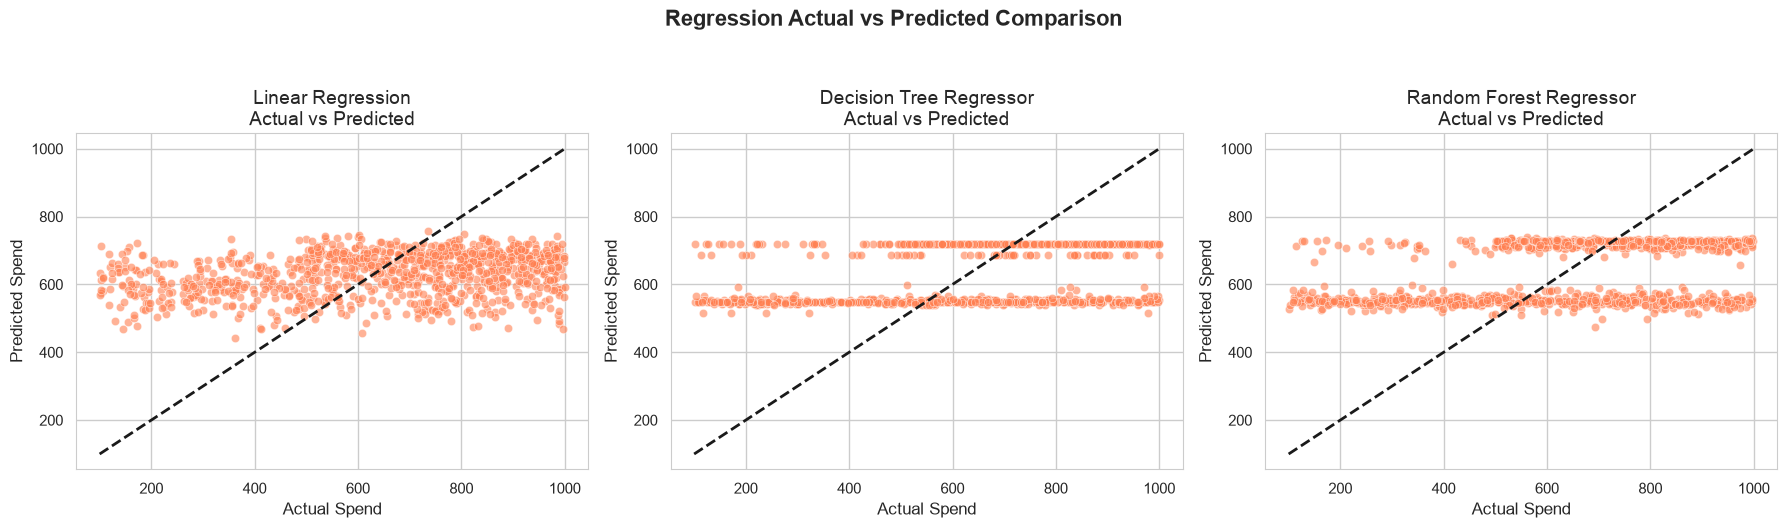

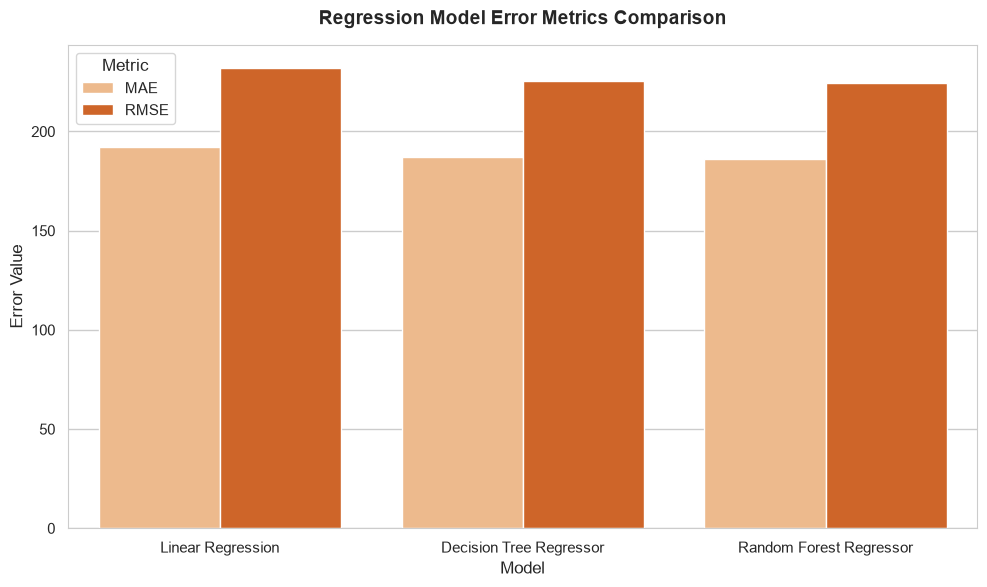

In [17]:
# 1. Actual vs Predicted Scatter Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, preds) in enumerate(reg_results.items()):
    # Plot a subset of 1000 points for visualization clarity
    subset_idx = np.random.choice(len(y_test_reg), size=1000, replace=False)
    y_true_sub = y_test_reg.iloc[subset_idx]
    y_pred_sub = preds[subset_idx]
    
    sns.scatterplot(x=y_true_sub, y=y_pred_sub, alpha=0.6, color='coral', ax=axes[idx])
    axes[idx].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'k--', lw=2)
    axes[idx].set_title(f'{name}\nActual vs Predicted', fontsize=14)
    axes[idx].set_xlabel('Actual Spend', fontsize=12)
    axes[idx].set_ylabel('Predicted Spend', fontsize=12)

plt.suptitle('Regression Actual vs Predicted Comparison', fontsize=16, y=1.05, weight='bold')
plt.tight_layout()
plt.savefig('plots/regression_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

# 2. Regression MAE/RMSE Comparison Bar Chart
df_melted_reg = df_reg_metrics.melt(id_vars='Model', value_vars=['MAE', 'RMSE'], var_name='Metric', value_name='Value')
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Value', hue='Metric', data=df_melted_reg, palette='Oranges')
plt.title('Regression Model Error Metrics Comparison', fontsize=14, weight='bold', pad=15)
plt.ylabel('Error Value', fontsize=12)
plt.xlabel('Model', fontsize=12)
plt.tight_layout()
plt.savefig('plots/regression_error_comparison.png', bbox_inches='tight')
plt.show()


## 4. Feature Importance Analysis

We inspect which features drive churn predictions using our Random Forest Classifier and Logistic Regression weights.


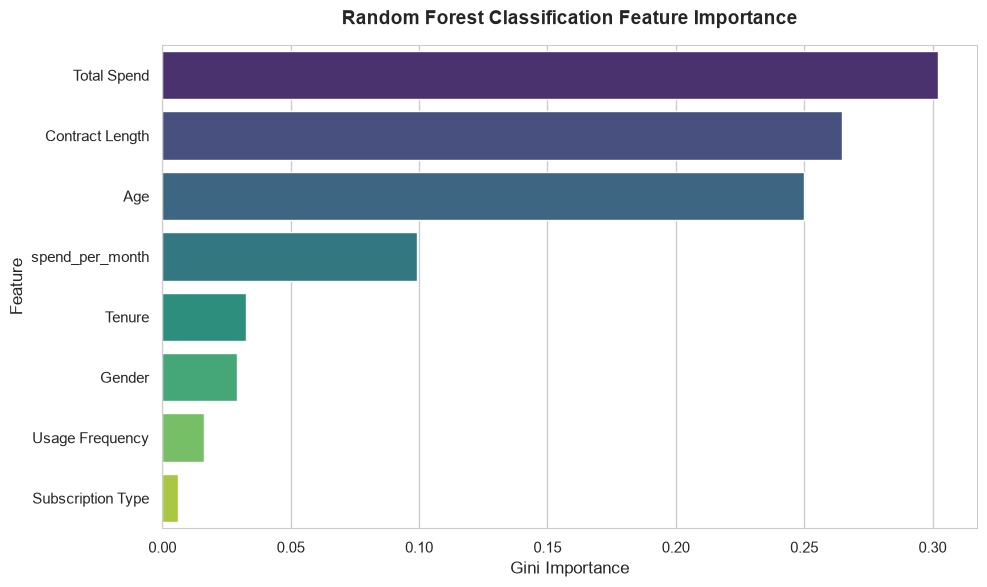

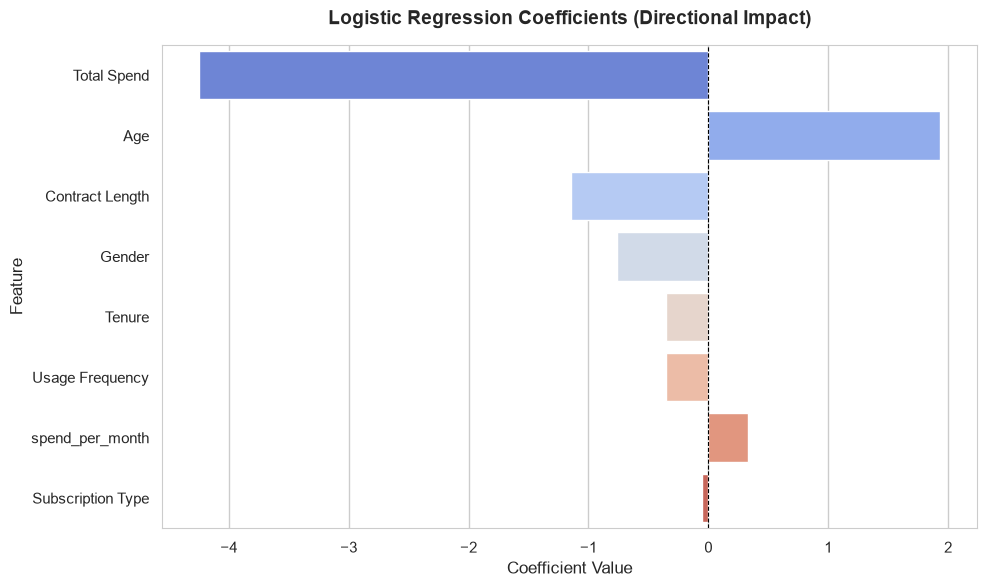

Random Forest Classifier Top Feature Importances:


,Feature,Importance
6,Total Spend,0.302196
5,Contract Length,0.264633
0,Age,0.249788
7,spend_per_month,0.099138
2,Tenure,0.032737



Logistic Regression Top Coefficients:


,Feature,Coefficient
6,Total Spend,-4.245146
0,Age,1.932257
5,Contract Length,-1.144002
1,Gender,-0.764903
2,Tenure,-0.352889


In [13]:
features = X_clf.columns

# 1. Random Forest Feature Importance
rf_importances = rf_clf.feature_importances_
rf_imp_df = pd.DataFrame({'Feature': features, 'Importance': rf_importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=rf_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Random Forest Classification Feature Importance', fontsize=14, weight='bold', pad=15)
plt.xlabel('Gini Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.savefig('plots/rf_feature_importance.png', bbox_inches='tight')
plt.show()

# 2. Logistic Regression Coefficients
lr_coefficients = log_reg.coef_[0]
lr_coeff_df = pd.DataFrame({'Feature': features, 'Coefficient': lr_coefficients}).sort_values(by='Coefficient', key=abs, ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=lr_coeff_df, hue='Feature', palette='coolwarm', legend=False)
plt.title('Logistic Regression Coefficients (Directional Impact)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Coefficient Value', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('plots/lr_coefficients.png', bbox_inches='tight')
plt.show()

print("Random Forest Classifier Top Feature Importances:")
display(rf_imp_df.head(5))
print("\nLogistic Regression Top Coefficients:")
display(lr_coeff_df.head(5))


## 5. Overfitting & Regularization Demo

We demonstrate how tree-based classifiers overfit without restrictions, and how we apply regularization (limiting `max_depth` for Decision Trees and increasing the L2 penalty `C` for Logistic Regression) to prevent this behavior.


Regularization Comparison Table:


,Model & Configuration,Parameters,Train Accuracy,Test Accuracy,Accuracy Gap
0,Decision Tree Classifier (Unconstrained),"max_depth=None (Depth: 130, Leaves: 42754)",1.000000,0.827078,0.172922
1,Decision Tree Classifier (Regularized),max_depth=5 (Leaves: 11),0.874402,0.873524,0.000878
2,Logistic Regression (Baseline),C=1.0,0.752215,0.753649,-0.001434
3,Logistic Regression (Regularized),C=0.01,0.752164,0.753377,-0.001213


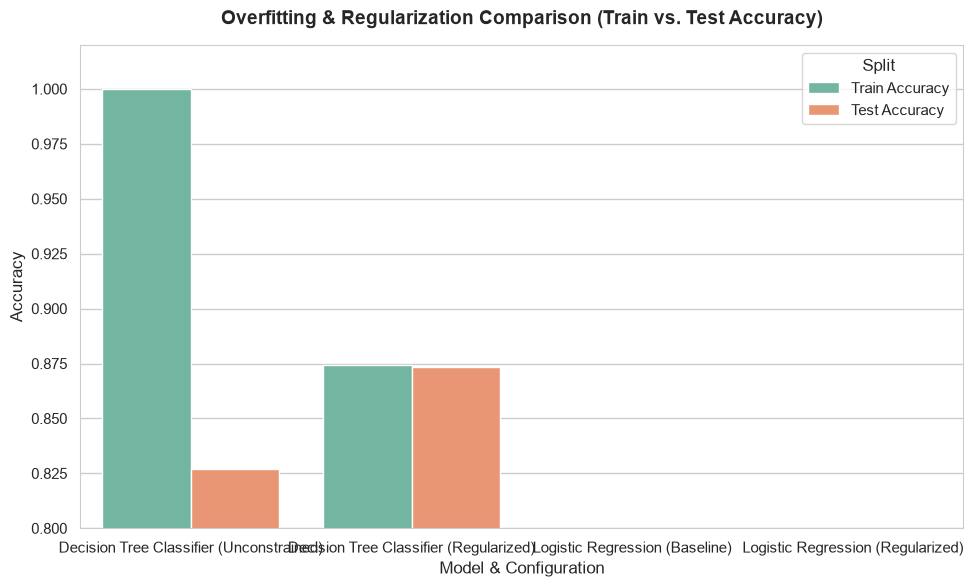

In [14]:
# 1. Unconstrained Decision Tree Classifier (Overfit)
dt_clf_overfit = DecisionTreeClassifier(random_state=42)
dt_clf_overfit.fit(X_train_clf_scaled, y_train_clf)

train_acc_overfit = accuracy_score(y_train_clf, dt_clf_overfit.predict(X_train_clf_scaled))
test_acc_overfit = accuracy_score(y_test_clf, dt_clf_overfit.predict(X_test_clf_scaled))

# 2. Regularized Decision Tree Classifier (max_depth=5)
dt_clf_reg = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_clf_reg.fit(X_train_clf_scaled, y_train_clf)

train_acc_reg = accuracy_score(y_train_clf, dt_clf_reg.predict(X_train_clf_scaled))
test_acc_reg = accuracy_score(y_test_clf, dt_clf_reg.predict(X_test_clf_scaled))

# 3. Logistic Regression Regularization (C=0.01 vs Baseline C=1.0)
log_reg_strong = LogisticRegression(C=0.01, max_iter=1000, random_state=42)
log_reg_strong.fit(X_train_clf_scaled, y_train_clf)

train_acc_lr_base = accuracy_score(y_train_clf, log_reg.predict(X_train_clf_scaled))
test_acc_lr_base = accuracy_score(y_test_clf, log_reg.predict(X_test_clf_scaled))

train_acc_lr_strong = accuracy_score(y_train_clf, log_reg_strong.predict(X_train_clf_scaled))
test_acc_lr_strong = accuracy_score(y_test_clf, log_reg_strong.predict(X_test_clf_scaled))

# Create overfitting comparison dataframe
overfit_data = [
    {
        'Model & Configuration': 'Decision Tree Classifier (Unconstrained)',
        'Parameters': f'max_depth=None (Depth: {dt_clf_overfit.get_depth()}, Leaves: {dt_clf_overfit.get_n_leaves()})',
        'Train Accuracy': train_acc_overfit,
        'Test Accuracy': test_acc_overfit,
        'Accuracy Gap': train_acc_overfit - test_acc_overfit
    },
    {
        'Model & Configuration': 'Decision Tree Classifier (Regularized)',
        'Parameters': f'max_depth=5 (Leaves: {dt_clf_reg.get_n_leaves()})',
        'Train Accuracy': train_acc_reg,
        'Test Accuracy': test_acc_reg,
        'Accuracy Gap': train_acc_reg - test_acc_reg
    },
    {
        'Model & Configuration': 'Logistic Regression (Baseline)',
        'Parameters': 'C=1.0',
        'Train Accuracy': train_acc_lr_base,
        'Test Accuracy': test_acc_lr_base,
        'Accuracy Gap': train_acc_lr_base - test_acc_lr_base
    },
    {
        'Model & Configuration': 'Logistic Regression (Regularized)',
        'Parameters': 'C=0.01',
        'Train Accuracy': train_acc_lr_strong,
        'Test Accuracy': test_acc_lr_strong,
        'Accuracy Gap': train_acc_lr_strong - test_acc_lr_strong
    }
]

df_overfit = pd.DataFrame(overfit_data)
print("Regularization Comparison Table:")
display(df_overfit.style.background_gradient(cmap='Oranges', subset=['Accuracy Gap']))

# Plot Overfitting Comparison (Train vs Test Accuracy)
df_overfit_melted = df_overfit.melt(id_vars='Model & Configuration', value_vars=['Train Accuracy', 'Test Accuracy'], var_name='Split', value_name='Accuracy')
plt.figure(figsize=(10, 6))
sns.barplot(x='Model & Configuration', y='Accuracy', hue='Split', data=df_overfit_melted, palette='Set2')
plt.ylim([0.8, 1.02])
plt.title('Overfitting & Regularization Comparison (Train vs. Test Accuracy)', fontsize=14, weight='bold', pad=15)
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Model & Configuration', fontsize=12)
plt.tight_layout()
plt.savefig('plots/overfitting_comparison.png', bbox_inches='tight')
plt.show()


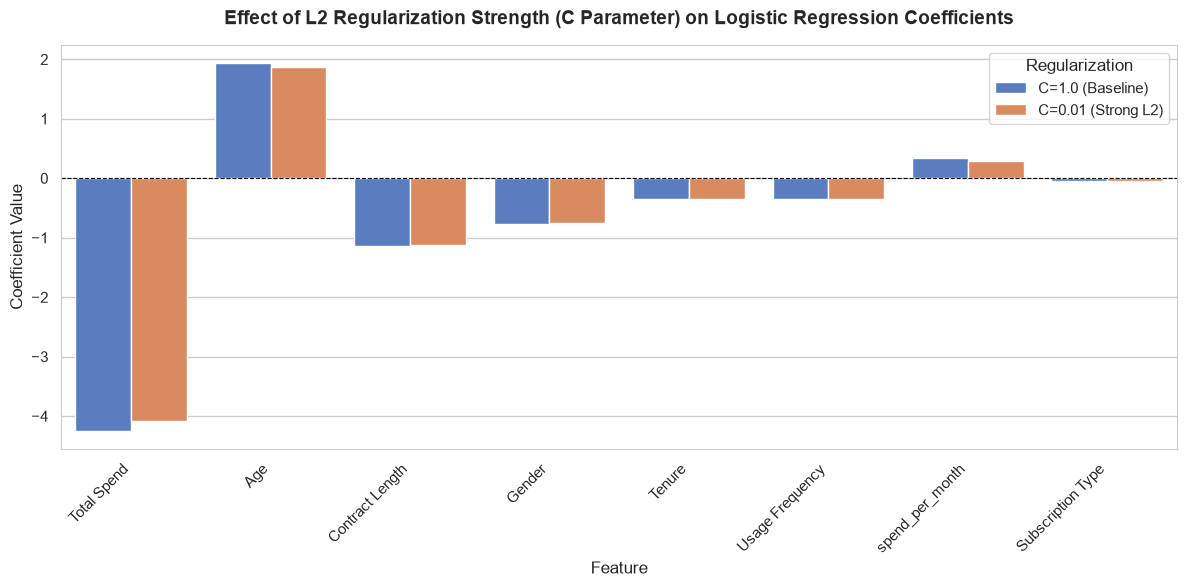

In [15]:
# Compare coefficients side by side to visualize shrinkage
coeff_compare = pd.DataFrame({
    'Feature': features,
    'C=1.0 (Baseline)': log_reg.coef_[0],
    'C=0.01 (Strong L2)': log_reg_strong.coef_[0]
}).sort_values(by='C=1.0 (Baseline)', key=abs, ascending=False)

coeff_melted = coeff_compare.melt(id_vars='Feature', var_name='Regularization', value_name='Coefficient')

plt.figure(figsize=(12, 6))
sns.barplot(x='Feature', y='Coefficient', hue='Regularization', data=coeff_melted, palette='muted')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Effect of L2 Regularization Strength (C Parameter) on Logistic Regression Coefficients', fontsize=14, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Coefficient Value', fontsize=12)
plt.tight_layout()
plt.savefig('plots/lr_coefficient_shrinkage.png', bbox_inches='tight')
plt.show()


## 6. Production Scoring Demo


In [16]:
# 1. Load the testing file
print("Loading production testing dataset...")
df_prod = pd.read_csv('customer_churn_dataset-testing-demo.csv')
print(f"Production dataset shape: {df_prod.shape}")

# Save CustomerIDs for output mapping
prod_ids = df_prod['CustomerID']

# 2. Preprocess
df_prod_clean = df_prod.copy()

# Categorical mapping
df_prod_clean['Contract Length'] = df_prod_clean['Contract Length'].map(contract_mapping)
df_prod_clean['Subscription Type'] = df_prod_clean['Subscription Type'].map(sub_mapping)
df_prod_clean['Gender'] = df_prod_clean['Gender'].map(gender_mapping)

# Feature engineering
df_prod_clean['spend_per_month'] = df_prod_clean['Total Spend'] / df_prod_clean['Tenure']

# Extract Features (dropping CustomerID, Churn, Last Interaction, Support Calls, Payment Delay)
X_prod = df_prod_clean.drop(columns=['CustomerID', 'Churn', 'Last Interaction', 'Support Calls', 'Payment Delay'], errors='ignore')

# 3. Apply Scaling using the scaler fit on training split
X_prod_scaled = X_prod.copy()
X_prod_scaled[clf_features_to_scale] = scaler_clf.transform(X_prod[clf_features_to_scale])

# 4. Generate Predictions using Random Forest Classifier
print("Generating predictions using Random Forest Classifier...")
prod_preds = rf_clf.predict(X_prod_scaled)
prod_probs = rf_clf.predict_proba(X_prod_scaled)[:, 1]

# 5. Save results to CSV
df_predictions_output = pd.DataFrame({
    'CustomerID': prod_ids.astype('int64'),
    'Churn_Predicted': prod_preds,
    'Churn_Probability': prod_probs
})

output_filepath = 'churn_predictions.csv'
df_predictions_output.to_csv(output_filepath, index=False)
print(f"Production scoring complete! Results saved to '{output_filepath}'.")

# Display a preview of the predictions
print("\nPreview of predictions output:")
display(df_predictions_output.head(10))


Loading production testing dataset...
Production dataset shape: (64374, 12)
Generating predictions using Random Forest Classifier...
Production scoring complete! Results saved to 'churn_predictions.csv'.

Preview of predictions output:


,CustomerID,Churn_Predicted,Churn_Probability
0,1,1,1.000000
1,2,1,1.000000
2,3,0,0.121026
3,4,1,0.996092
4,5,1,0.985462
5,6,1,1.000000
6,7,0,0.243305
7,8,1,1.000000
8,9,1,1.000000
9,10,1,0.985779
